In [7]:
print(df.columns.tolist())

['report_number', 'date_reported', 'date_of_occurrence', 'time_of_occurrence', 'city', 'crime_code', 'crime_description', 'victim_age', 'victim_gender', 'weapon_used', 'crime_domain', 'police_deployed', 'case_closed', 'date_case_closed', 'year', 'month', 'month_name', 'day', 'day_of_week', 'occurrence_hour', 'time_period', 'reporting_delay_days', 'age_group', 'case_resolution_days']


In [8]:
import pandas as pd

# Load your processed dataset first
df = pd.read_csv(r'C:\Users\Vidisha Mankar\Desktop\DMBIPROJECT\CrimeMapX\data\processed\crime_data_processed.csv')

# Now run your breakdown
crime_breakdown = df['crime_domain'].value_counts()
print(crime_breakdown)

crime_domain
Property & Financial Crime    15303
Violent & Personal Crime      13452
Public Order & Cyber           9490
Traffic & Regulatory           1915
Name: count, dtype: int64


In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data_path = Path("data/processed/crime_data_processed.csv")
if not data_path.is_file():
    data_path = Path("../data/processed/crime_data_processed.csv")
if not data_path.is_file():
    raise FileNotFoundError(f"Processed crime dataset not found: {data_path.resolve()}")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape}")
df.head()


Dataset Shape: (40160, 24)


,report_number,date_reported,date_of_occurrence,time_of_occurrence,city,crime_code,crime_description,victim_age,victim_gender,weapon_used,...,year,month,month_name,day,day_of_week,occurrence_hour,time_period,reporting_delay_days,age_group,case_resolution_days
0,1,2020-01-02 00:00:00,2020-01-01 00:00:00,01-01-2020 01:11,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,...,2020,1,January,1,Wednesday,1,Night,1.000000,Minor,NaN
1,2,2020-01-01 19:00:00,2020-01-01 01:00:00,01-01-2020 06:26,Chennai,128,HOMICIDE,37,M,Poison,...,2020,1,January,1,Wednesday,6,Morning,0.750000,Adult,NaN
2,3,2020-01-02 05:00:00,2020-01-01 02:00:00,01-01-2020 14:30,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,...,2020,1,January,1,Wednesday,14,Afternoon,1.125000,Adult,NaN
3,4,2020-01-01 05:00:00,2020-01-01 03:00:00,01-01-2020 14:46,Pune,170,BURGLARY,49,F,Firearm,...,2020,1,January,1,Wednesday,14,Afternoon,0.083333,Adult,119.083333
4,5,2020-01-01 21:00:00,2020-01-01 04:00:00,01-01-2020 16:51,Pune,421,VANDALISM,30,F,Other,...,2020,1,January,1,Wednesday,16,Afternoon,0.708333,Young Adult,7.708333


C:\Users\Vidisha Mankar\AppData\Local\Temp\ipykernel_11572\4160432779.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='victim_gender', data=df, ax=axes[1], palette='Set2')


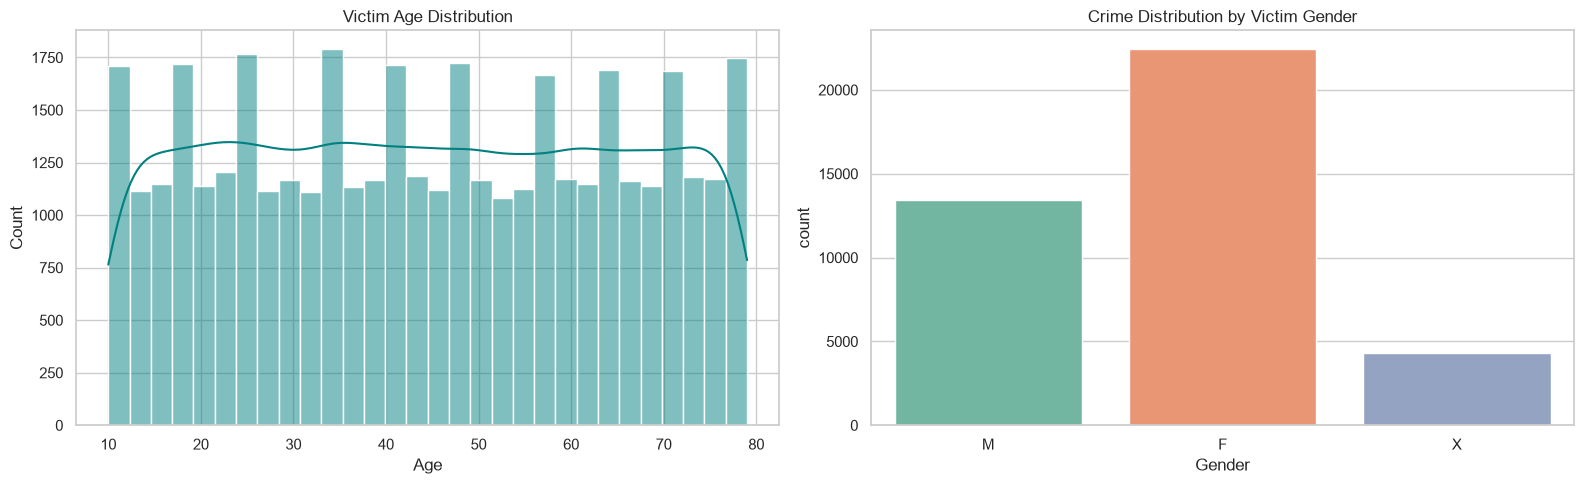

C:\Users\Vidisha Mankar\AppData\Local\Temp\ipykernel_11572\4160432779.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cities.index, y=top_cities.values, palette='rocket')


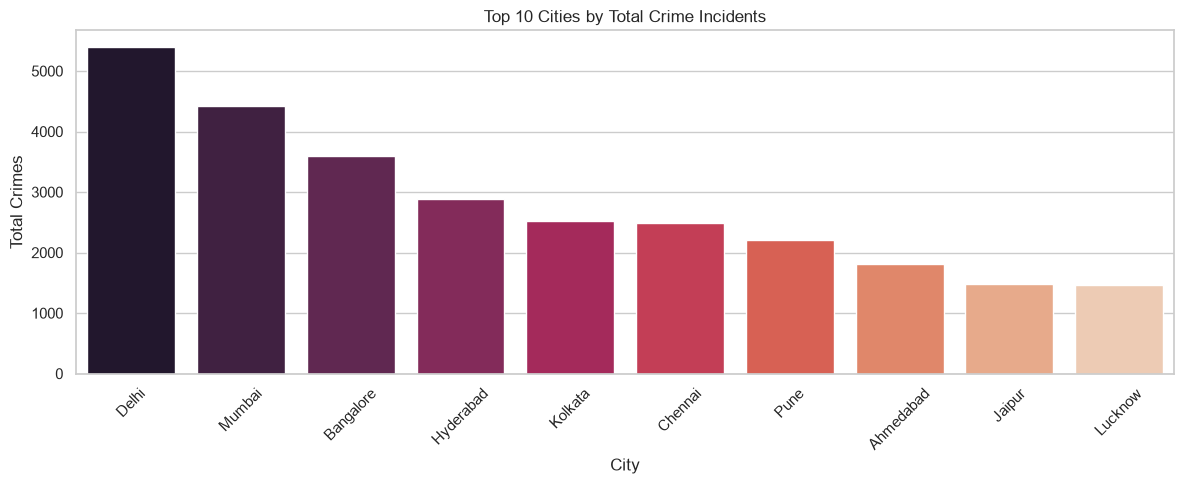

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Victim Age Distribution
if 'victim_age' in df.columns:
    sns.histplot(df['victim_age'].dropna(), bins=30, kde=True, ax=axes[0], color='teal')
    axes[0].set_title('Victim Age Distribution')
    axes[0].set_xlabel('Age')

# Victim Gender Breakdown
if 'victim_gender' in df.columns:
    sns.countplot(x='victim_gender', data=df, ax=axes[1], palette='Set2')
    axes[1].set_title('Crime Distribution by Victim Gender')
    axes[1].set_xlabel('Gender')

plt.tight_layout()
plt.show()

# Top Cities by Crime Count
if 'city' in df.columns:
    plt.figure(figsize=(12, 5))
    top_cities = df['city'].value_counts().head(10)
    sns.barplot(x=top_cities.index, y=top_cities.values, palette='rocket')
    plt.title('Top 10 Cities by Total Crime Incidents')
    plt.xlabel('City')
    plt.ylabel('Total Crimes')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

C:\Users\Vidisha Mankar\AppData\Local\Temp\ipykernel_11572\1033490381.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_domains.values, y=top_domains.index, ax=axes[0], palette='crest')
C:\Users\Vidisha Mankar\AppData\Local\Temp\ipykernel_11572\1033490381.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_weapons.values, y=top_weapons.index, ax=axes[1], palette='muted')


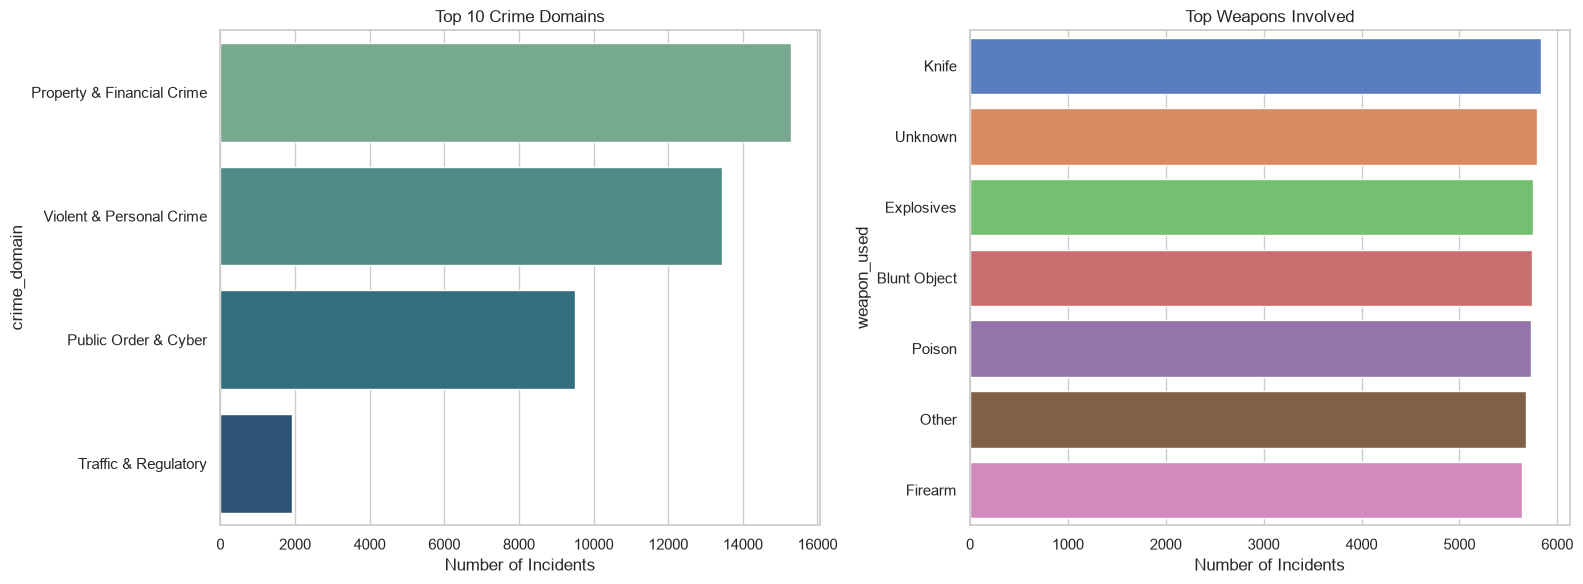

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top Crime Domains
if 'crime_domain' in df.columns:
    top_domains = df['crime_domain'].value_counts().head(10)
    sns.barplot(x=top_domains.values, y=top_domains.index, ax=axes[0], palette='crest')
    axes[0].set_title('Top 10 Crime Domains')
    axes[0].set_xlabel('Number of Incidents')

# Top Weapons Used
if 'weapon_used' in df.columns:
    top_weapons = df['weapon_used'].value_counts().head(8)
    sns.barplot(x=top_weapons.values, y=top_weapons.index, ax=axes[1], palette='muted')
    axes[1].set_title('Top Weapons Involved')
    axes[1].set_xlabel('Number of Incidents')

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Crimes by Hour
if 'occurrence_hour' in df.columns:
    sns.countplot(x='occurrence_hour', data=df, ax=axes[0], palette='viridis')
    axes[0].set_title('Crime Distribution by Hour of Day')
    axes[0].set_xlabel('Hour (0-23)')
    axes[0].set_ylabel('Incident Count')

# 2. Crimes by Day of Week
if 'day_of_week' in df.columns:
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    sns.countplot(x='day_of_week', data=df, order=day_order, ax=axes[1], palette='magma')
    axes[1].set_title('Crime Distribution by Day of Week')
    axes[1].set_xlabel('Day')
    axes[1].set_ylabel('Incident Count')
    axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [6]:
# Check columns and data types
print("--- Data Info ---")
print(df.info())

# Summary statistics for numerical columns (like Victim Age)
print("\n--- Summary Statistics ---")
display(df.describe())

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 40160 entries, 0 to 40159
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   report_number         40160 non-null  int64  
 1   date_reported         40160 non-null  str    
 2   date_of_occurrence    40160 non-null  str    
 3   time_of_occurrence    40160 non-null  str    
 4   city                  40160 non-null  str    
 5   crime_code            40160 non-null  int64  
 6   crime_description     40160 non-null  str    
 7   victim_age            40160 non-null  int64  
 8   victim_gender         40160 non-null  str    
 9   weapon_used           40160 non-null  str    
 10  crime_domain          40160 non-null  str    
 11  police_deployed       40160 non-null  int64  
 12  case_closed           40160 non-null  str    
 13  date_case_closed      20062 non-null  str    
 14  year                  40160 non-null  int64  
 15  month       

,report_number,crime_code,victim_age,police_deployed,year,month,day,occurrence_hour,reporting_delay_days,case_resolution_days
count,40160.000000,40160.000000,40160.00000,40160.000000,40160.000000,40160.000000,40160.000000,40160.000000,32480.000000,17271.000000
mean,20080.500000,349.360259,44.49126,10.006250,2021.816335,6.328287,15.597211,11.496564,27.601814,116.323623
std,11593.337742,144.169205,20.22555,5.467951,1.336053,3.426416,8.920962,6.901710,61.980840,145.627986
min,1.000000,100.000000,10.00000,1.000000,2020.000000,1.000000,1.000000,0.000000,0.041667,0.041667
25%,10040.750000,225.000000,27.00000,5.000000,2021.000000,3.000000,7.000000,5.000000,0.958333,32.520833
50%,20080.500000,349.000000,44.00000,10.000000,2022.000000,6.000000,16.000000,11.000000,1.875000,64.791667
75%,30120.250000,474.000000,62.00000,15.000000,2023.000000,9.000000,23.000000,17.000000,2.833333,125.916667
max,40160.000000,599.000000,79.00000,19.000000,2024.000000,12.000000,31.000000,23.000000,326.958333,1028.125000
